# Imports

In [1]:
import os
import warnings
from rich import print

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

import scanpy as sc
import palantir
import scvi
import torch

In [2]:
# helper function import for pairwise analysis
import sys
sys.path.append('./utils/')
from pairwise_differential_expression import pairwise_differential_analysis, add_pairwise_results_to_anndata, plot_pairwise_results

In [3]:
plt.rcParams['savefig.dpi'] = 300
%matplotlib inline

# Functions

In [4]:
# For clustering, perform PFlog normalization
from scipy.io import mmread
from scipy.optimize import curve_fit

In [5]:
def overdispersion(mtx):                     # fit var = mu + alpha*mu^2 across genes
    """Fit var = mu + alpha*mu^2 across genes to estimate NB overdispersion."""
    mu  = np.asarray(mtx.mean(0)).ravel()
    m2  = mtx.copy(); m2.data **= 2
    var = np.asarray(m2.mean(0)).ravel() - mu**2
    return curve_fit(lambda x, a: x + a * x**2, mu, var)[0][0]

In [6]:
def apply_pflog(adata, counts_layer="raw_counts"):
    """
    Apply PFlog (shifted CLR) normalization to raw counts in an AnnData object.
    Stores result in adata.layers["pflog"].
    """
    import scipy.sparse as sp

    # Pull raw counts — must be sparse for overdispersion()
    mtx = adata.layers[counts_layer]
    if not sp.issparse(mtx):
        mtx = sp.csr_matrix(mtx)
    else:
        mtx = mtx.tocsr()

    # Estimate overdispersion and pseudocount
    alpha = overdispersion(mtx)
    y0    = 1 / (4 * alpha)
    print(f"alpha = {alpha:.4f}, pseudocount y0 = {y0:.4f}")

    # Apply shifted log then CLR centering
    # NOTE: toarray() here — fine for datasets that fit in memory
    shifted_log = np.log(mtx.toarray() + y0)
    cell_mean   = shifted_log.mean(axis=1)
    pflog       = shifted_log - cell_mean[:, None]

    adata.layers["pflog"] = pflog
    print("Done. PFlog stored in adata.layers['pflog']")
    return alpha, y0

# Load Data

In [7]:
combined_ad = sc.read_h5ad('concatenated_data.h5ad')
combined_ad.shape

(7944, 32101)

# Normalization

In [8]:
alpha, y0 = apply_pflog(combined_ad, counts_layer="raw_counts")

alpha = 0.7530, pseudocount y0 = 0.3320

Done. PFlog stored in adata.layers['pflog']

# Feature Selection

In [9]:
sc.pp.highly_variable_genes(
    combined_ad,
    flavor="seurat_v3",   # operates on raw counts
    n_top_genes=3000,
    batch_key="batch",  # find HVGs consistent across batches
    subset=False,
    layer='raw_counts'
)

# Batch Correction

In [10]:
combined_ad_not_corrected = combined_ad.copy()

## No Correction

In [11]:
sc.pp.pca(combined_ad_not_corrected, layer="pflog", n_comps=50, svd_solver="arpack", mask_var="highly_variable")

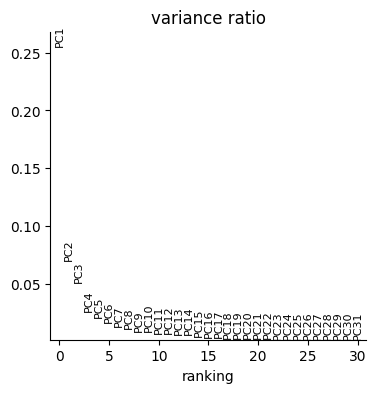

In [12]:
sc.pl.pca_variance_ratio(combined_ad_not_corrected, n_pcs=30)

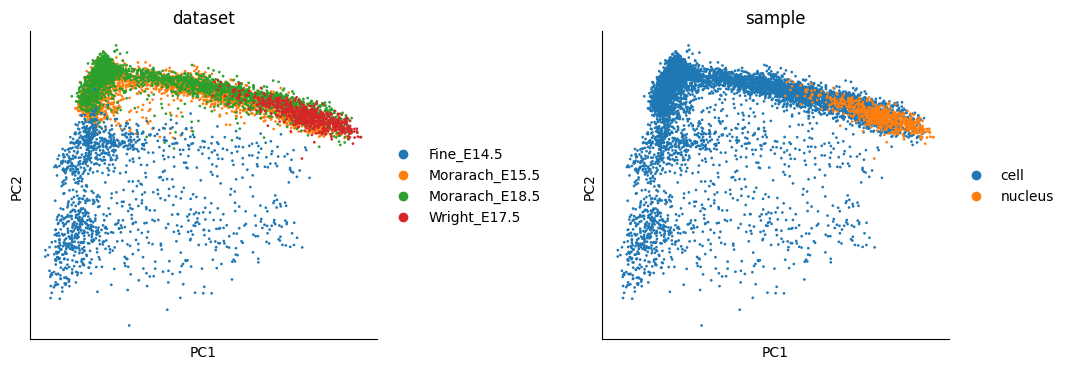

In [13]:
sc.pl.pca(combined_ad_not_corrected, color=["dataset", "sample"], wspace=0.5)

In [14]:
sc.pp.neighbors(combined_ad_not_corrected, use_rep="X_pca", n_neighbors=15, n_pcs=10)

In [15]:
sc.tl.umap(combined_ad_not_corrected, min_dist=0.5, spread=1.0)

In [16]:
sc.tl.leiden(combined_ad_not_corrected, resolution=0.5)

/loc/scratch/64411177/ipykernel_25715/3922955757.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(combined_ad_not_corrected, resolution=0.5)


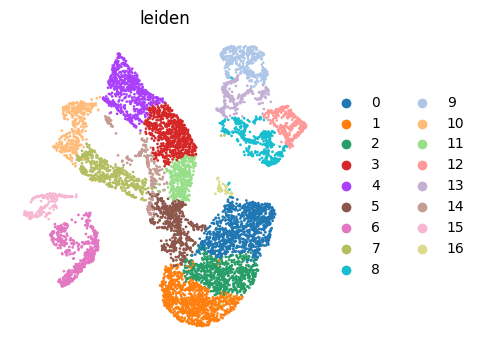

In [17]:
sc.pl.umap(combined_ad_not_corrected, color=["leiden"], frameon=False)

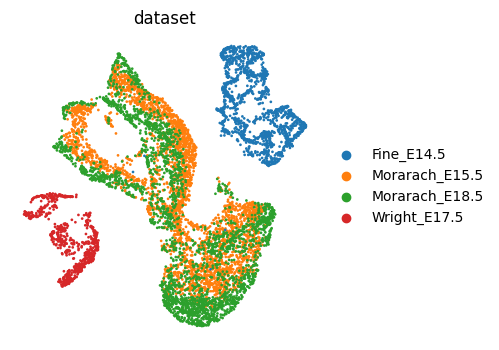

In [18]:
sc.pl.umap(combined_ad_not_corrected, color=['dataset'], frameon=False, wspace=0.5)

## Correction

In [19]:
combined_ad_corrected = combined_ad.copy()

In [20]:
scvi.model.SCVI.setup_anndata(
    combined_ad_corrected,
    layer="raw_counts",
    batch_key="dataset",                      # your technical batch variable
    # categorical_covariate_keys=["sample"],  # optional, finer-grained nuisance var
    continuous_covariate_keys=None,           # e.g. ["pct_counts_mt"] if you want
)

In [21]:
model = scvi.model.SCVI(combined_ad_corrected, n_layers=2, n_latent=30, gene_likelihood="nb")
model.train()  # add max_epochs=400 if you want to force it; default has early stopping

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
SLURM auto-requeueing enabled. Setting signal handlers.
/home/bnguyen3/.local/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


In [22]:
combined_ad_corrected.obsm["X_scVI"] = model.get_latent_representation()

sc.pp.neighbors(combined_ad_corrected, use_rep="X_scVI")
sc.tl.umap(combined_ad_corrected)

In [49]:
sc.tl.leiden(combined_ad_corrected, resolution=0.2)

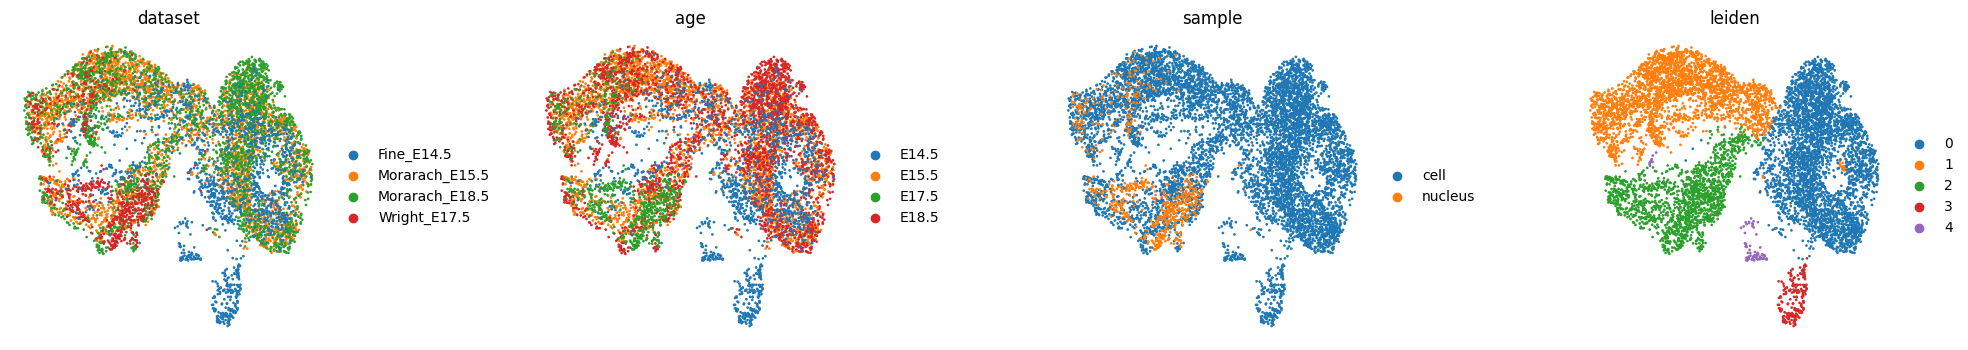

In [50]:
sc.pl.umap(combined_ad_corrected, color=["dataset", "age", "sample", "leiden"], frameon=False, wspace=0.5)

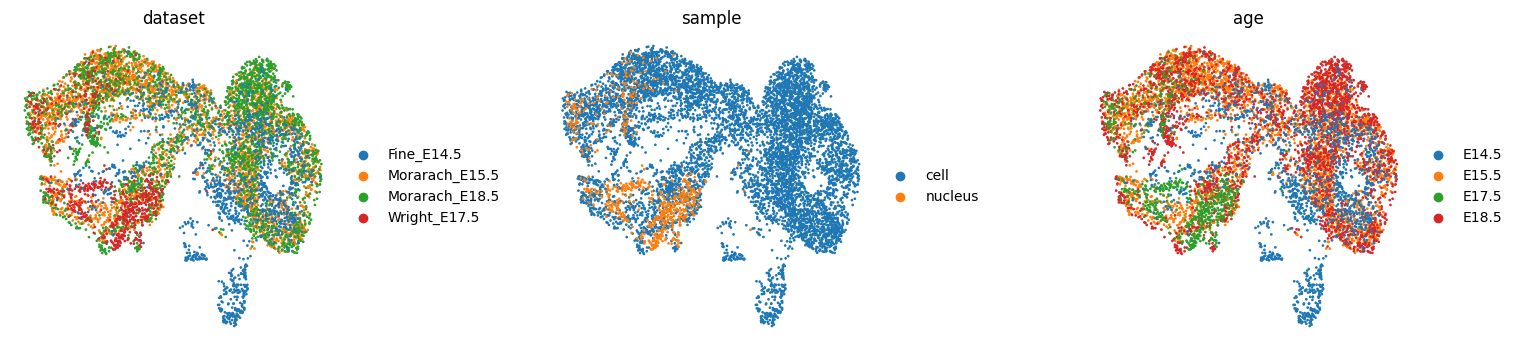

In [27]:
sc.pl.umap(combined_ad_corrected, color=['dataset', 'sample', 'age'], frameon=False, wspace=0.5, save='_metadata.png')

# PairDEX Analysis

## Run

In [28]:
pairdex_ad = combined_ad_corrected.copy()

In [29]:
pairdex_ad.X = pairdex_ad.layers['log_counts'].copy()

In [30]:
LEIDEN_NAME = 'leiden'
ARG_PAIRWISE_LOG_FC_MIN = 1.5
ARG_PAIRWISE_PVAL_CUTOFF = 1e-25

In [31]:
import tqdm

# package the arguments
clusters = pairdex_ad.obs[LEIDEN_NAME].unique()

# Pairwise analysis per cluster
# N x (N-1) computation will be done
target_cluster_results = []
for cluster in tqdm.tqdm(clusters):
    result = pairwise_differential_analysis(pairdex_ad, cluster, 
                                LEIDEN_NAME, ARG_PAIRWISE_LOG_FC_MIN, ARG_PAIRWISE_PVAL_CUTOFF)
    target_cluster_results += result
    
# Consolidate pairwise results via concatenation each pairwise results should be accessible by 'group'
df_mp = pd.concat(target_cluster_results, axis=0)

  0%|          | 0/5 [00:00<?, ?it/s]/app/software/scanpy/1.10.4-foss-2024a/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/app/software/scanpy/1.10.4-foss-2024a/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/app/software/scanpy/1.10.4-foss-2024a/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/app/software/scanpy/1.10.4-foss-2024a/lib/python3.12/site-packages/scanpy/tools/_rank_genes_groups.py:455: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
 20%|██        | 1/5 [00:04<00:16,  4.00s/it]/app/software/scanpy/1.10.4-foss-2024a/lib/python3.12/site-packages/sc

In [32]:
df_mp

,names,scores,logfoldchanges,pvals,pvals_adj,group,compared_against
0,Meg3,65.741180,6.428443,0.000000e+00,0.000000e+00,1,0
1,6330403K07Rik,62.334896,4.695457,0.000000e+00,0.000000e+00,1,0
2,Calm1,60.733646,2.640543,0.000000e+00,0.000000e+00,1,0
3,Cpe,58.947472,6.341470,0.000000e+00,0.000000e+00,1,0
4,Tubb2b,54.177067,4.384077,0.000000e+00,0.000000e+00,1,0
...,...,...,...,...,...,...,...
379,Sox18,-55.451950,2.864228,1.843576e-281,7.786927e-279,3,2
380,Hoxc8,-62.827396,2.564995,0.000000e+00,0.000000e+00,3,2
0,Ppbp,-18.680599,1.814266,1.529928e-41,1.227805e-37,3,4
1,Six2,-28.420305,1.508729,2.251977e-69,3.614536e-65,3,4


In [33]:
df_mp_GroupCounts = df_mp.loc[:,['names','group']].groupby(['group','names']).agg({'names':'count'}).rename(columns={'names':'gene_counts'})

In [34]:
df_mp_GroupCounts

gene_counts
group names                     
0     0610007P14Rik            2
      0610009O20Rik            1
      0610011F06Rik            2
      0610037L13Rik            2
      1110001J03Rik            1
...                          ...
4     Tspo2                    2
      Upk1b                    2
      Upk3b                    2
      Wnt4                     1
      Wt1                      2

[2559 rows x 1 columns]

In [35]:
leiden_name = LEIDEN_NAME
pairwise_counts_matrix = pd.DataFrame(0, index=pairdex_ad.var_names, columns=pairdex_ad.obs[leiden_name].values.categories)
cluster_list = pairdex_ad.obs[leiden_name].values.categories.tolist()
for cluster in tqdm.tqdm(cluster_list, total=len(cluster_list), desc='Adding count values'):
    clust_specific_genes = df_mp_GroupCounts.loc[cluster,:].index.tolist()
    clust_specific_genes_count = df_mp_GroupCounts.loc[cluster].values.ravel()
    pairwise_counts_matrix.loc[clust_specific_genes,cluster] = clust_specific_genes_count

Adding count values: 100%|██████████| 5/5 [00:00<00:00, 168.03it/s]


In [36]:
# Add to anndata
add_pairwise_results_to_anndata(pairdex_ad, df_mp, LEIDEN_NAME)

Adding count values: 100%|██████████| 5/5 [00:00<00:00, 790.93it/s]
/fh/fast/talbot_j/grp/TalbotLab/Current_Lab_Members/Brandon_Nguyen/Project/Results/BN019_Embryonic_Meta_Atlas/utils/pairwise_differential_expression.py:123: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_expression_matrix = expression_matrix.groupby('leiden_cluster').mean()


## Analyze Cluster of Interest

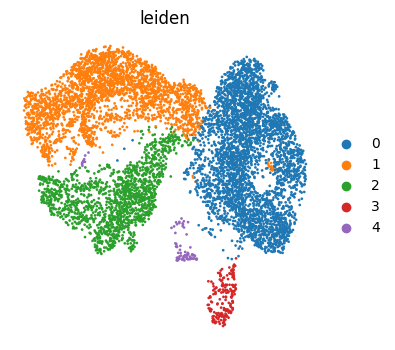

In [37]:
sc.pl.umap(pairdex_ad, color=['leiden'], frameon=False)

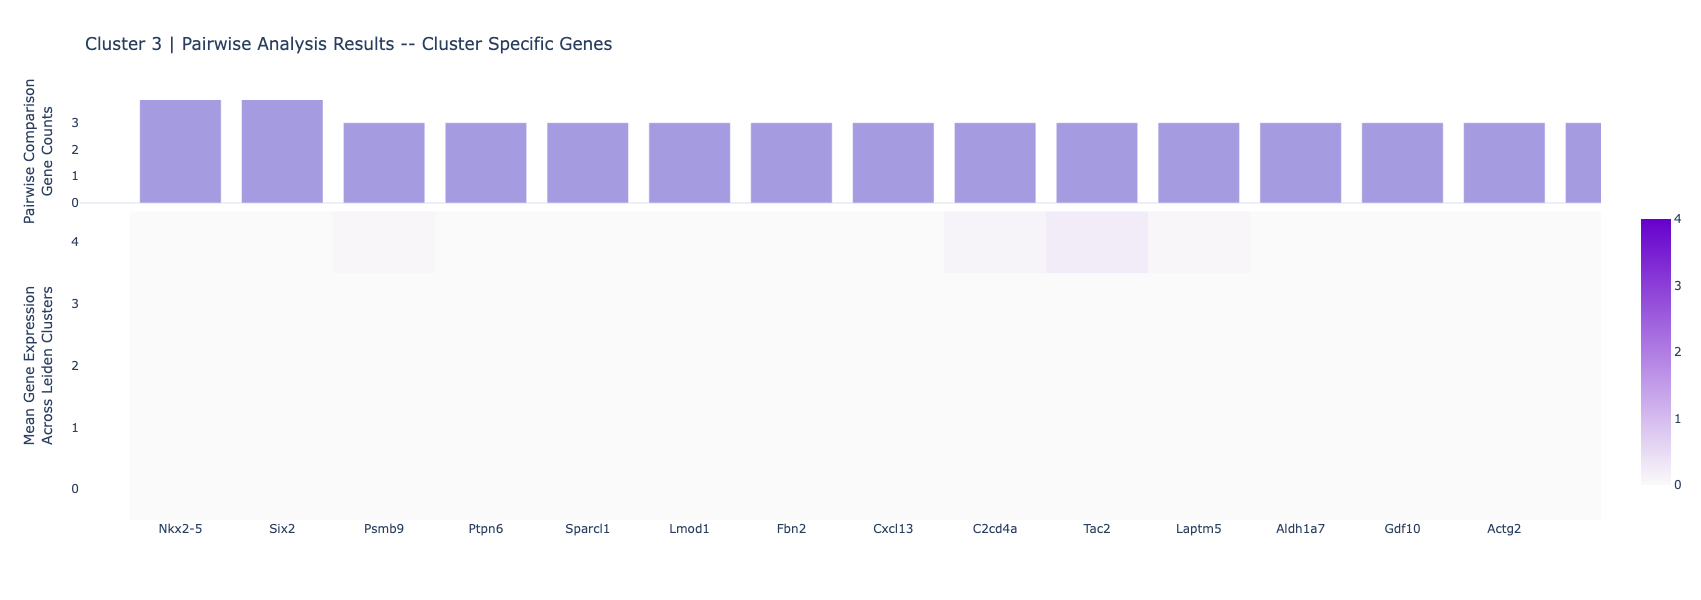

In [39]:
plot_pairwise_results(pairdex_ad, '3', save=None)

# Celltype Annotation

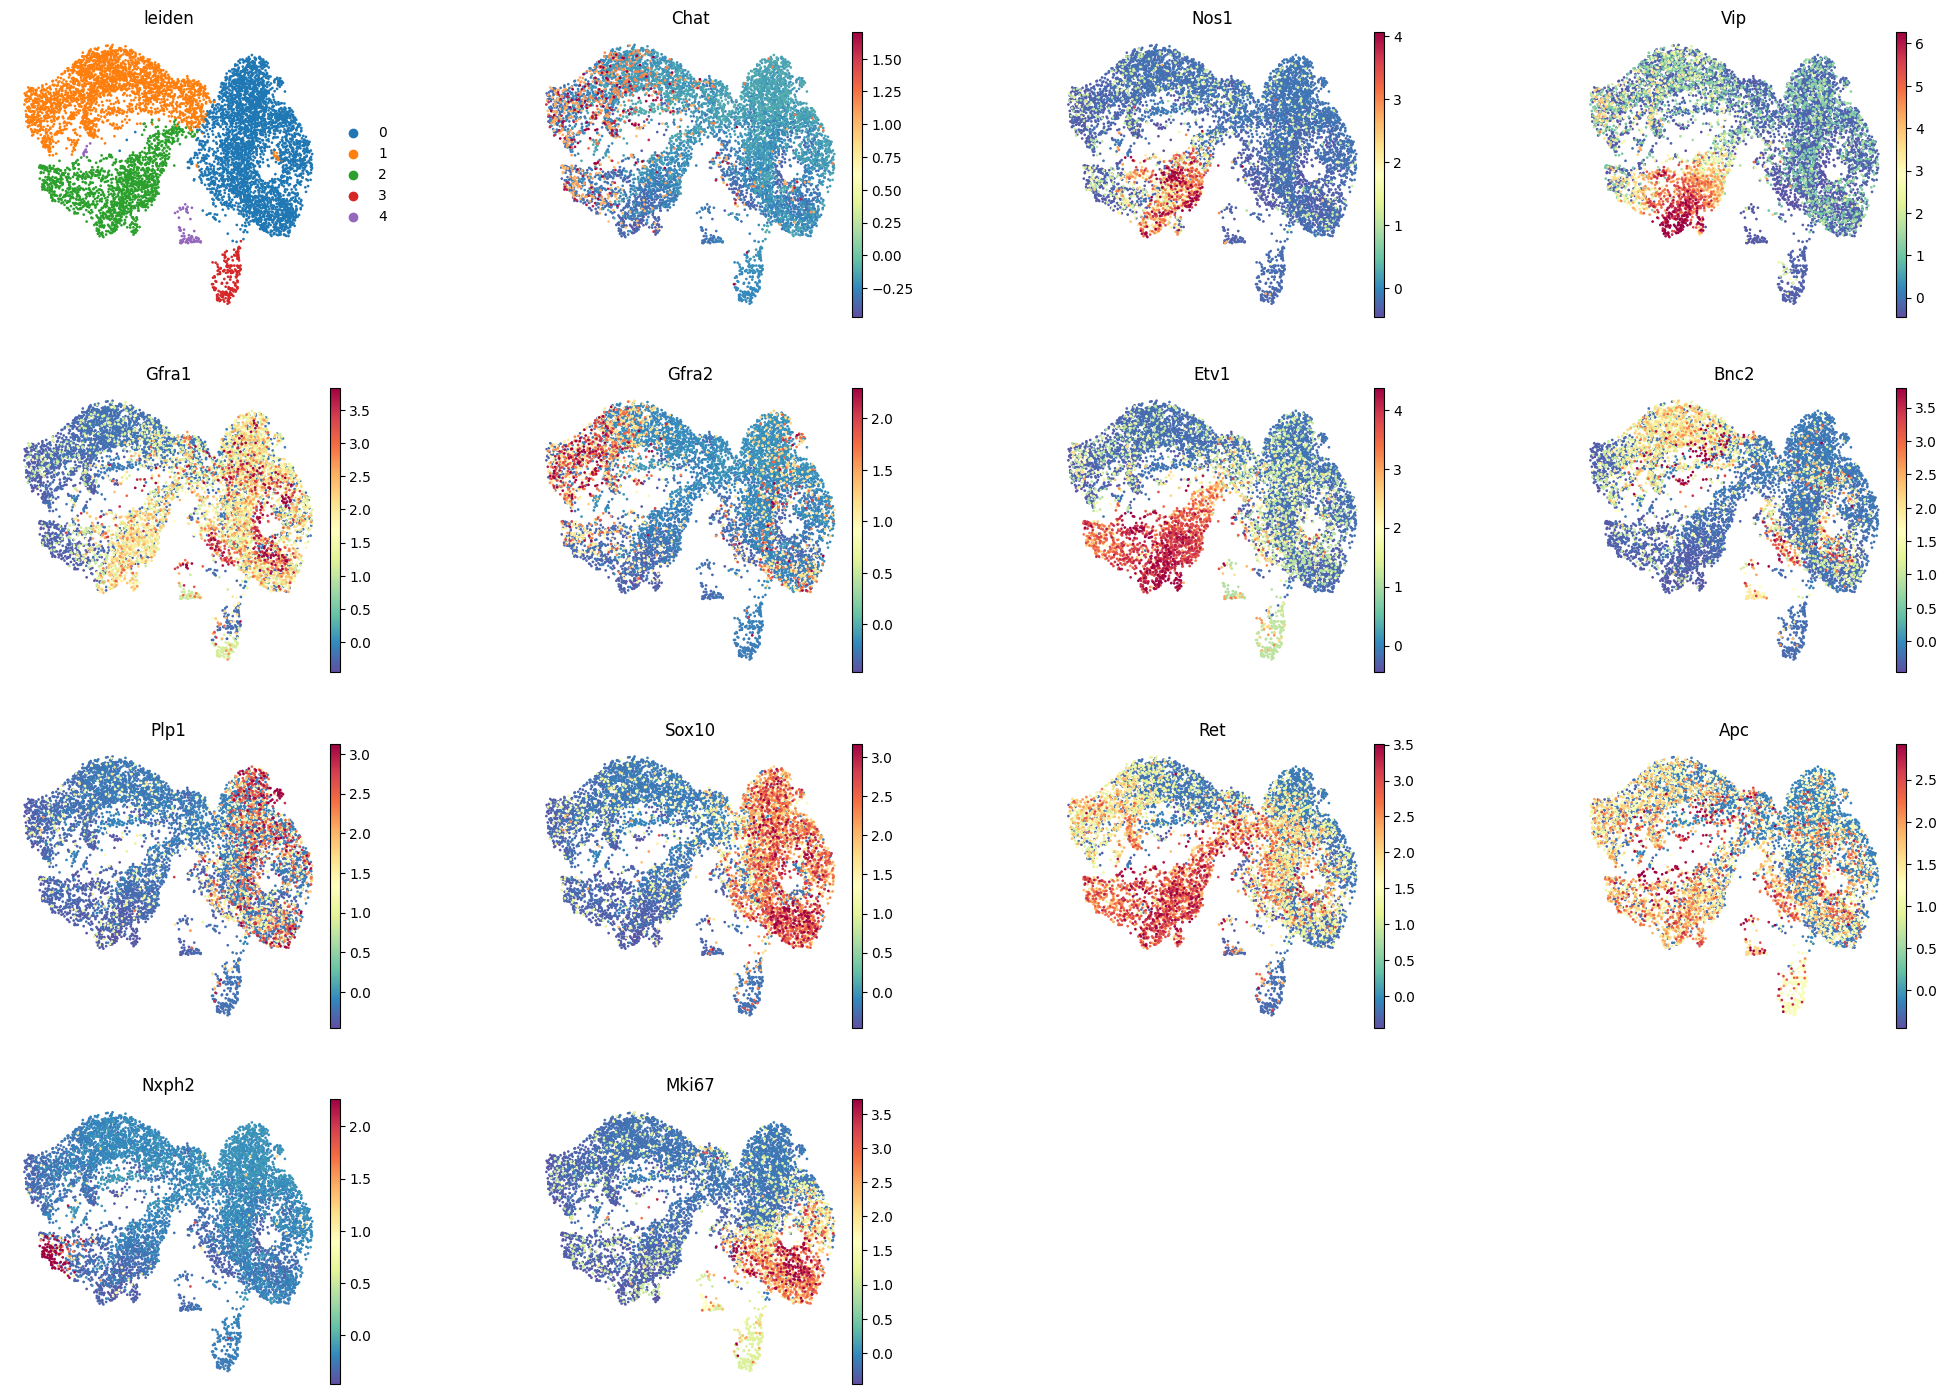

In [43]:
sc.pl.umap(combined_ad_corrected, color=['leiden', 'Chat', 'Nos1', 'Vip',
                                         'Gfra1', 'Gfra2',
                                         'Etv1', 'Bnc2',
                                         'Plp1', 'Sox10',
                                         'Ret', 'Apc',
                                         'Nxph2',
                                         'Mki67'], wspace=0.5, vmax='p99', layer='pflog', frameon=False, save='_markers.png')

In [51]:
leiden_to_celltype = {
    '0': 'Glial/Progenitor',
    '2': 'Branch A Neuron',
    '1': 'Branch B Neuron',
}

combined_ad_corrected.obs['celltype'] = combined_ad_corrected.obs['leiden'].map(leiden_to_celltype)

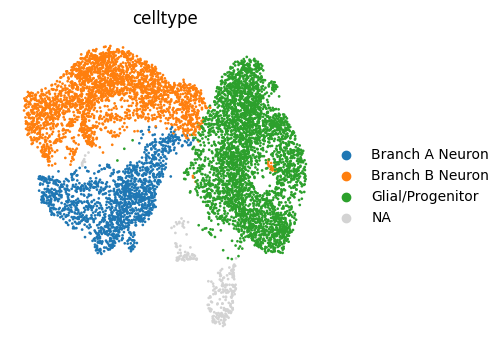

In [52]:
sc.pl.umap(combined_ad_corrected, color='celltype', frameon=False, save='_annotations.png')

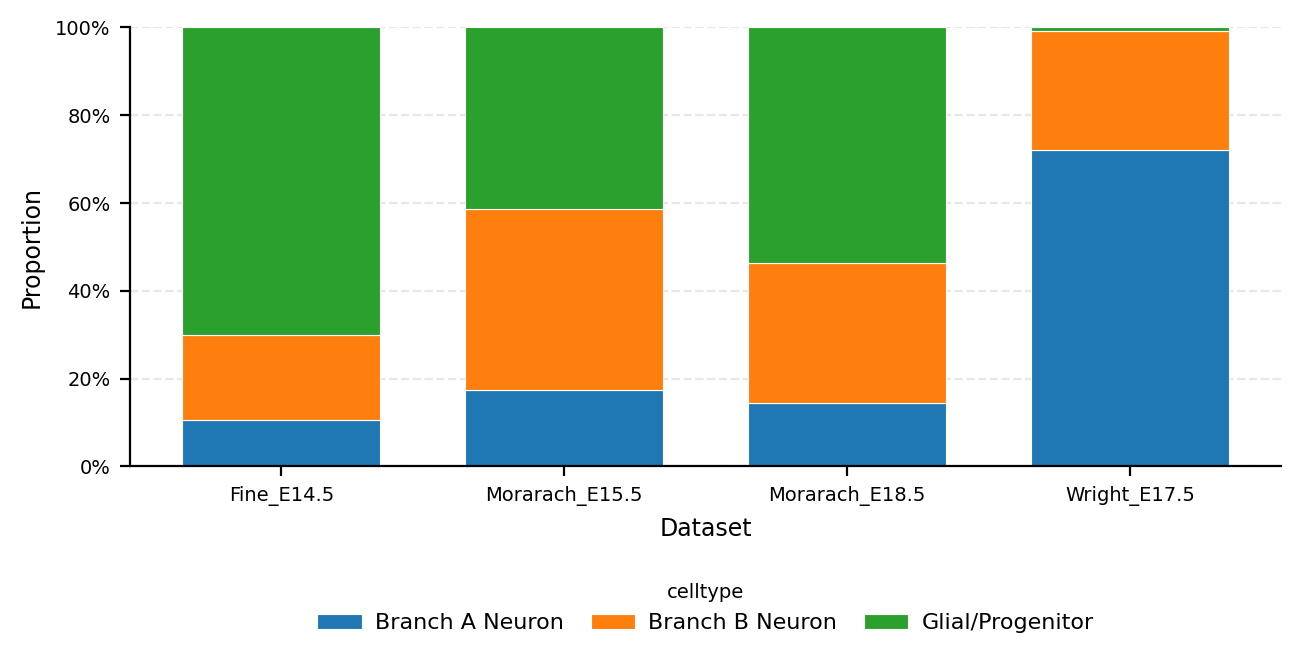

In [54]:
import matplotlib.ticker as mtick

adata = combined_ad_corrected

# --- region × leiden proportions ---
prop_table = pd.crosstab(
    adata.obs['dataset'],
    adata.obs['celltype'],
    normalize='index'
)

# --- use Scanpy's leiden colors to match your UMAP ---
# (Scanpy stores them in adata.uns['leiden_colors'])
if 'celltype_colors' in adata.uns:
    cat_order = list(adata.obs['celltype'].cat.categories)
    color_map = dict(zip(cat_order, adata.uns['celltype_colors']))
    colors = [color_map[c] for c in prop_table.columns]
else:
    # fallback: tab20
    colors = plt.cm.tab20(np.linspace(0, 1, prop_table.shape[1]))

fig, ax = plt.subplots(figsize=(7, 4), dpi=200)

bottom = np.zeros(len(prop_table))

for cluster, color in zip(prop_table.columns, colors):
    ax.bar(
        prop_table.index,
        prop_table[cluster],
        bottom=bottom,
        label=cluster,
        width=0.7,
        edgecolor='white',
        linewidth=0.4,
        color=color,
    )
    bottom += prop_table[cluster].values

# --- axis formatting ---
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.2))  # 0, 20, 40, 60, 80, 100%
ax.set_ylabel('Proportion', fontsize=8.5)
ax.set_xlabel('Dataset', fontsize=8.5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='both', labelsize=7)

# Light horizontal gridlines behind bars
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)

# --- legend below plot ---
ax.legend(
    title='celltype',
    bbox_to_anchor=(0.5, -0.22),
    loc='upper center',
    frameon=False,
    ncol=4,         # fewer columns = tighter rows
    fontsize=8,
    title_fontsize=7,
    handletextpad=0.6,
    columnspacing=1.2,
    borderpad=0.4
)

plt.tight_layout(pad=2.5)
plt.show()

# Save AnnData Object

In [56]:
combined_ad_corrected.write_h5ad('embryonic_meta_atlas.h5ad')